In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [ ]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [10]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.all

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [ ]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
def plot_maps_tele_delta(x, y, z, titles, labels, cmap, levels, pval = [], pval2=[], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        if pval2 != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval[i] <= 0.05, True, False)
            # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_tele_delta(x, y, z, title, label, cmap, levels, add_sign=False, pval = [],  pval2 = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        pval_plot = np.ma.masked_less_equal(pval, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        pval_plot = np.ma.masked_less_equal(pval2, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [13]:
import matplotlib.colors as mcolors

In [ ]:
def plot_teleconnection_robustness(
    field,
    lon, lat,
    snr_model=None,
    snr_obs=None,
    pval_model=None,
    snr_threshold=1.5,
    pval_threshold=0.05,
    use_pval=False,
    cmap='RdBu_r',
    vmin=None,
    vmax=None,
    title_main='',
    title_suffix='',
    cbar_label='',
):
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes
    from matplotlib.patches import Patch

    xx, yy = np.meshgrid(lon, lat)

    # --- Robustness masks ---
    if use_pval:
        mask_model = pval_model <= pval_threshold
        mask_obs   = snr_obs > snr_threshold if snr_obs is not None else None
    else:
        mask_model = snr_model > snr_threshold
        mask_obs   = snr_obs   > snr_threshold

    mask_both = mask_model & mask_obs if mask_obs is not None else mask_model

    # --- Figure ---
    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5),
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180))
    )

    # ===========================
    # Panel A: signal field
    # ===========================
    im = axes[0].pcolormesh(
        xx, yy, field.values,
        cmap=cmap, vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree()
    )

    # Colorbar via inset_axes
    cax = inset_axes(axes[0], width='70%', height='5%',
                     loc='lower center', borderpad=-2.5)
    plt.colorbar(im, cax=cax, orientation='horizontal', label=cbar_label)

    # Stippling
    axes[0].scatter(
        xx[mask_both.values], yy[mask_both.values],
        s=2, color='k', marker='.',
        transform=ccrs.PlateCarree(), zorder=5
    )
    axes[0].set_title(title_main)
    plot_background(axes[0])

    # ===========================
    # Panel B: categorical map
    # ===========================
    if mask_obs is not None:
        base       = np.where(~mask_model.values & ~mask_obs.values, 1, np.nan)
        model_only = np.where( mask_model.values & ~mask_obs.values, 1, np.nan)
        obs_only   = np.where(~mask_model.values &  mask_obs.values, 1, np.nan)
        both       = np.where( mask_both.values,                     1, np.nan)

        axes[1].pcolormesh(xx, yy, base,
                           cmap=mcolors.ListedColormap(['lightgrey']),
                           vmin=0, vmax=1,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, model_only,
                           cmap=mcolors.ListedColormap(['tab:blue']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, obs_only,
                           cmap=mcolors.ListedColormap(['tab:orange']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, both,
                           cmap=mcolors.ListedColormap(['tab:blue']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, both,
                           cmap=mcolors.ListedColormap(['tab:orange']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())
        # Both — single solid color
        both_color = '#7B4F9E'  # clear purple
        axes[1].pcolormesh(xx, yy, both,
                   cmap=mcolors.ListedColormap([both_color]),
                   vmin=0, vmax=1, alpha=0.8,
                   transform=ccrs.PlateCarree())
                   # Update legend
        legend_elements = [
            Patch(facecolor='lightgrey',               label='Neither'),
            Patch(facecolor='tab:blue',   alpha=0.6,   label='Model only'),
            Patch(facecolor='tab:orange', alpha=0.6,   label='Obs only'),
            Patch(facecolor='#7B4F9E',    alpha=0.8,   label='Both'),
        ]
    else:
        base   = np.where(~mask_both.values, 1, np.nan)
        robust = np.where( mask_both.values, 1, np.nan)

        axes[1].pcolormesh(xx, yy, base,
                           cmap=mcolors.ListedColormap(['lightgrey']),
                           vmin=0, vmax=1,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, robust,
                           cmap=mcolors.ListedColormap(['tab:red']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())

        legend_elements = [
            Patch(facecolor='lightgrey',           label='Not robust'),
            Patch(facecolor='tab:red', alpha=0.6,  label='Robust'),
        ]

    axes[1].legend(handles=legend_elements, loc='lower left',
                   fontsize=8, framealpha=0.9)
    axes[1].set_title(title_suffix)
    plot_background(axes[1])

    plt.tight_layout()
    # return fig

In [ ]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Patch

def plot_composite(field, lon, lat, vmin=-1.0, vmax=1.0,
                   cmap='RdBu_r', cbar_label='', title=''):
    
    xx, yy = np.meshgrid(lon, lat)
    
    fig, ax = plt.subplots(
        figsize=(8, 4),
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180))
    )
    im = ax.pcolormesh(
        xx, yy, field.values,
        cmap=cmap, vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree()
    )
    cax = inset_axes(ax, width='60%', height='5%',
                     loc='lower center', borderpad=-2.5)
    plt.colorbar(im, cax=cax, orientation='horizontal', label=cbar_label)
    ax.set_title(title)
    plot_background(ax)
    plt.tight_layout()
    # return fig


def plot_baseline_teleconnection(
    field,
    lon, lat,
    sig_data,
    mode='cmip6',
    p_threshold=0.05,
    agreement_threshold=0.8,
    cmap='RdBu_r',
    vmin=-1.0,
    vmax=1.0,
    cbar_label='',
    title='',
):
    xx, yy = np.meshgrid(lon, lat)

    fig, ax = plt.subplots(
        figsize=(8, 4),
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180))
    )

    im = ax.pcolormesh(
        xx, yy, field.values,
        cmap=cmap, vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree()
    )

    cax = inset_axes(ax, width='60%', height='5%',
                     loc='lower center', borderpad=-2.5)
    plt.colorbar(im, cax=cax, orientation='horizontal', label=cbar_label)

    # --- Agreement / significance ---
    sig = sig_data <= p_threshold
    if mode == 'cmip6':
        agreement = sig.mean('model')
    elif mode == 'smile':
        sig_stacked = sig.stack(ensemble=('model', 'smile'))
        agreement   = sig_stacked.mean('ensemble')
    else:
        raise ValueError("mode must be 'cmip6' or 'smile'")

    mask = agreement >= agreement_threshold
    ax.scatter(
        xx[mask.values], yy[mask.values],
        s=1, marker='.', color='k',
        transform=ccrs.PlateCarree(), zorder=5
    )

    ax.set_title(title)
    plot_background(ax)
    plt.tight_layout()
    # return fig

In [17]:
import sys

In [18]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [19]:
from functions import preproc_funcs as funcs

In [20]:
model_list = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM',
    
]

In [21]:
# model_list_alt = [
#     'ACCESS-ESM1-5',
#     'CESM1-CAM5',
#     'CESM2', # ssp3
#     'CSIRO-Mk3-6-0',
#     'CanESM2',
#     'CanESM5_p1',
#     'E3SM-1-0', # ssp3
#     'E3SMv2', # ssp3
#     'GFDL-CM3',
#     'GFDL-ESM2M',
#     'GFDL-SPEAR-MED',
#     'MIROC6',
#     'MPI-ESM',
#     'UKESM1-0-LL', # ssp3
# ]

In [22]:
ts_regr_obs_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_obs_1950_2014.nc')
# ts_regr_rean_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_rean_1950_2014.nc')

ts_regr_obs_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_30.nc')
# ts_regr_rean_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_30_rean.nc')

In [23]:
delta_ts_regr_obs = (ts_regr_obs_30y.regr - ts_regr_obs_baseline.regr)
# delta_ts_regr_rean = (ts_regr_rean_30y.regr - ts_regr_rean_baseline.regr)

In [24]:
ts_regr_cmip6_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_baseline.nc')
ts_regr_cmip6_midc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_mid_century.nc')
ts_regr_cmip6_endc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_end_century.nc')
# ts_regr_cmip6_regr15 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr15.nc')
# ts_regr_cmip6_regr20 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr20.nc')
# ts_regr_cmip6_regr30 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr30.nc')
# ts_regr_cmip6_regr40 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr40.nc')

In [25]:
delta_ts_regr_cmip6_midc  = (ts_regr_cmip6_midc.regr - ts_regr_cmip6_baseline.regr)
delta_ts_regr_cmip6_endc  = (ts_regr_cmip6_endc.regr - ts_regr_cmip6_baseline.regr)
# delta_ts_regr_cmip6_regr15  = (ts_regr_cmip6_regr15.drop_sel(model = 'NESM3').regr - ts_regr_cmip6_baseline.drop_sel(model = 'NESM3').regr)
# delta_ts_regr_cmip6_regr20  = (ts_regr_cmip6_regr20.drop_sel(model = 'NESM3').regr - ts_regr_cmip6_baseline.drop_sel(model = 'NESM3').regr)
# delta_ts_regr_cmip6_regr30  = (ts_regr_cmip6_regr30.drop_sel(model = 'NESM3').regr - ts_regr_cmip6_baseline.drop_sel(model = 'NESM3').regr)
# delta_ts_regr_cmip6_regr40  = (ts_regr_cmip6_regr40.drop_sel(model = 'NESM3').regr - ts_regr_cmip6_baseline.drop_sel(model = 'NESM3').regr)

In [26]:
def _preprocess(da):
    if 'height' in da.coords:
        da = da.drop('height')
    return da

In [27]:

## calculating model_uncertainty and internal variabiltiy uncertainty
ts_regr_smile_baseline_means = []
ts_regr_smile_baseline_vars = []

delta_ts_regr_smile_midc_means = []
delta_ts_regr_smile_midc_vars = []

delta_ts_regr_smile_endc_means = []
delta_ts_regr_smile_endc_vars = []

# delta_ts_regr_smile_regr15_means = []
# delta_ts_regr_smile_regr15_vars = []

# delta_ts_regr_smile_regr20_means = []
# delta_ts_regr_smile_regr20_vars = []

# delta_ts_regr_smile_regr30_means = []
# delta_ts_regr_smile_regr30_vars = []

# delta_ts_regr_smile_regr40_means = []
# delta_ts_regr_smile_regr40_vars = []



for model in model_list:
    ts_regr_smile_baseline = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_baseline.nc', preprocess=_preprocess).regr
    ts_regr_smile_baseline_means.append(ts_regr_smile_baseline.mean('model'))
    ts_regr_smile_baseline_vars.append(ts_regr_smile_baseline.var('model'))
    #
    delta_ts_regr_smile_midc = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_mid_century.nc', preprocess=_preprocess).regr - ts_regr_smile_baseline
    delta_ts_regr_smile_midc_means.append(delta_ts_regr_smile_midc.mean('model'))
    delta_ts_regr_smile_midc_vars.append(delta_ts_regr_smile_midc.var('model'))
    #
    delta_ts_regr_smile_endc = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_end_century.nc', preprocess=_preprocess).regr - ts_regr_smile_baseline
    delta_ts_regr_smile_endc_means.append(delta_ts_regr_smile_endc.mean('model'))
    delta_ts_regr_smile_endc_vars.append(delta_ts_regr_smile_endc.var('model'))
    # #
    # delta_ts_regr_smile_regr15 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr15.nc', preprocess=_preprocess).regr - ts_regr_smile_baseline
    # delta_ts_regr_smile_regr15_means.append(delta_ts_regr_smile_regr15.mean('model'))
    # delta_ts_regr_smile_regr15_vars.append(delta_ts_regr_smile_regr15.var('model'))
    # #
    # delta_ts_regr_smile_regr20 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr20.nc', preprocess=_preprocess).regr - ts_regr_smile_baseline
    # delta_ts_regr_smile_regr20_means.append(delta_ts_regr_smile_regr20.mean('model'))
    # delta_ts_regr_smile_regr20_vars.append(delta_ts_regr_smile_regr20.var('model'))
    # #
    # delta_ts_regr_smile_regr30 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr30.nc', preprocess=_preprocess).regr - ts_regr_smile_baseline
    # delta_ts_regr_smile_regr30_means.append(delta_ts_regr_smile_regr30.mean('model'))
    # delta_ts_regr_smile_regr30_vars.append(delta_ts_regr_smile_regr30.var('model'))
    # #
    # delta_ts_regr_smile_regr40 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr40.nc', preprocess=_preprocess).regr - ts_regr_smile_baseline
    # delta_ts_regr_smile_regr40_means.append(delta_ts_regr_smile_regr40.mean('model'))
    # delta_ts_regr_smile_regr40_vars.append(delta_ts_regr_smile_regr40.var('model'))
    #
    print(f'Completed {model}')


ts_regr_smile_baseline_means = xr.concat(ts_regr_smile_baseline_means, dim='smile')
ts_regr_smile_baseline_means['smile'] = model_list
ts_regr_smile_baseline_vars = xr.concat(ts_regr_smile_baseline_vars, dim='smile')
ts_regr_smile_baseline_vars['smile'] = model_list

delta_ts_regr_smile_midc_means = xr.concat(delta_ts_regr_smile_midc_means, dim='smile').load()
delta_ts_regr_smile_midc_means['smile'] = model_list
delta_ts_regr_smile_midc_vars = xr.concat(delta_ts_regr_smile_midc_vars, dim='smile').load()
delta_ts_regr_smile_midc_vars['smile'] = model_list

delta_ts_regr_smile_endc_means = xr.concat(delta_ts_regr_smile_endc_means, dim='smile').load()
delta_ts_regr_smile_endc_means['smile'] = model_list
delta_ts_regr_smile_endc_vars = xr.concat(delta_ts_regr_smile_endc_vars, dim='smile').load()
delta_ts_regr_smile_endc_vars['smile'] = model_list

# delta_ts_regr_smile_regr15_means = xr.concat(delta_ts_regr_smile_regr15_means, dim='smile').load()
# delta_ts_regr_smile_regr15_means['smile'] = model_list
# delta_ts_regr_smile_regr15_vars = xr.concat(delta_ts_regr_smile_regr15_vars, dim='smile').load()
# delta_ts_regr_smile_regr15_vars['smile'] = model_list

# delta_ts_regr_smile_regr20_means = xr.concat(delta_ts_regr_smile_regr20_means, dim='smile').load()
# delta_ts_regr_smile_regr20_means['smile'] = model_list
# delta_ts_regr_smile_regr20_vars = xr.concat(delta_ts_regr_smile_regr20_vars, dim='smile').load()
# delta_ts_regr_smile_regr20_vars['smile'] = model_list

# delta_ts_regr_smile_regr30_means = xr.concat(delta_ts_regr_smile_regr30_means, dim='smile').load()
# delta_ts_regr_smile_regr30_means['smile'] = model_list
# delta_ts_regr_smile_regr30_vars = xr.concat(delta_ts_regr_smile_regr30_vars, dim='smile').load()
# delta_ts_regr_smile_regr30_vars['smile'] = model_list

# delta_ts_regr_smile_regr40_means = xr.concat(delta_ts_regr_smile_regr40_means, dim='smile').load()
# delta_ts_regr_smile_regr40_means['smile'] = model_list
# delta_ts_regr_smile_regr40_vars = xr.concat(delta_ts_regr_smile_regr40_vars, dim='smile').load()
# delta_ts_regr_smile_regr40_vars['smile'] = model_list

print('DONE')

Completed ACCESS-ESM1-5
Completed CESM1-CAM5
Completed CSIRO-Mk3-6-0
Completed CanESM2
Completed CanESM5_p1
Completed GFDL-CM3
Completed GFDL-ESM2M
Completed GFDL-SPEAR-MED
Completed MIROC6
Completed MPI-ESM
DONE


In [28]:
## calculating model_uncertainty and internal variabiltiy uncertainty
ts_regr_smile_baseline_pvals = []
delta_ts_regr_smile_midc_pvals = []

delta_ts_regr_smile_endc_pvals = []

# delta_ts_regr_smile_regr15_pvals = []
# delta_ts_regr_smile_regr15_vars = []

# delta_ts_regr_smile_regr20_pvals = []
# delta_ts_regr_smile_regr20_vars = []

# delta_ts_regr_smile_regr30_pvals = []
# delta_ts_regr_smile_regr30_vars = []

# delta_ts_regr_smile_regr40_pvals = []
# delta_ts_regr_smile_regr40_vars = []



for model in model_list:
    ts_regr_smile_baseline_pval = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_baseline.nc', preprocess=_preprocess).pval
    ts_regr_smile_baseline_pvals.append(ts_regr_smile_baseline_pval)
    #
    delta_ts_regr_smile_midc_pval = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_mid_century.nc', preprocess=_preprocess).pval
    delta_ts_regr_smile_midc_pvals.append(delta_ts_regr_smile_midc_pval)
    #
    delta_ts_regr_smile_endc_pval = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_end_century.nc', preprocess=_preprocess).pval
    delta_ts_regr_smile_endc_pvals.append(delta_ts_regr_smile_endc_pval)
    # #
    # delta_ts_regr_smile_regr15 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr15.nc', preprocess=_preprocess).regr - ts_regr_smile_baseline
    # delta_ts_regr_smile_regr15_pvals.append(delta_ts_regr_smile_regr15.mean('model'))
    # delta_ts_regr_smile_regr15_vars.append(delta_ts_regr_smile_regr15.var('model'))
    # #
    # delta_ts_regr_smile_regr20 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr20.nc', preprocess=_preprocess).regr - ts_regr_smile_baseline
    # delta_ts_regr_smile_regr20_pvals.append(delta_ts_regr_smile_regr20.mean('model'))
    # delta_ts_regr_smile_regr20_vars.append(delta_ts_regr_smile_regr20.var('model'))
    # #
    # delta_ts_regr_smile_regr30 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr30.nc', preprocess=_preprocess).regr - ts_regr_smile_baseline
    # delta_ts_regr_smile_regr30_pvals.append(delta_ts_regr_smile_regr30.mean('model'))
    # delta_ts_regr_smile_regr30_vars.append(delta_ts_regr_smile_regr30.var('model'))
    # #
    # delta_ts_regr_smile_regr40 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr40.nc', preprocess=_preprocess).regr - ts_regr_smile_baseline
    # delta_ts_regr_smile_regr40_pvals.append(delta_ts_regr_smile_regr40.mean('model'))
    # delta_ts_regr_smile_regr40_vars.append(delta_ts_regr_smile_regr40.var('model'))
    #
    print(f'Completed {model}')


ts_regr_smile_baseline_pvals = xr.concat(ts_regr_smile_baseline_pvals, dim='smile').load()
ts_regr_smile_baseline_pvals['smile'] = model_list

delta_ts_regr_smile_midc_pvals = xr.concat(delta_ts_regr_smile_midc_pvals, dim='smile').load()
delta_ts_regr_smile_midc_pvals['smile'] = model_list

delta_ts_regr_smile_endc_pvals = xr.concat(delta_ts_regr_smile_endc_pvals, dim='smile').load()
delta_ts_regr_smile_endc_pvals['smile'] = model_list

# delta_ts_regr_smile_regr15_pvals = xr.concat(delta_ts_regr_smile_regr15_pvals, dim='smile').load()
# delta_ts_regr_smile_regr15_pvals['smile'] = model_list
# delta_ts_regr_smile_regr15_vars = xr.concat(delta_ts_regr_smile_regr15_vars, dim='smile').load()
# delta_ts_regr_smile_regr15_vars['smile'] = model_list

# delta_ts_regr_smile_regr20_pvals = xr.concat(delta_ts_regr_smile_regr20_pvals, dim='smile').load()
# delta_ts_regr_smile_regr20_pvals['smile'] = model_list
# delta_ts_regr_smile_regr20_vars = xr.concat(delta_ts_regr_smile_regr20_vars, dim='smile').load()
# delta_ts_regr_smile_regr20_vars['smile'] = model_list

# delta_ts_regr_smile_regr30_pvals = xr.concat(delta_ts_regr_smile_regr30_pvals, dim='smile').load()
# delta_ts_regr_smile_regr30_pvals['smile'] = model_list
# delta_ts_regr_smile_regr30_vars = xr.concat(delta_ts_regr_smile_regr30_vars, dim='smile').load()
# delta_ts_regr_smile_regr30_vars['smile'] = model_list

# delta_ts_regr_smile_regr40_pvals = xr.concat(delta_ts_regr_smile_regr40_pvals, dim='smile').load()
# delta_ts_regr_smile_regr40_pvals['smile'] = model_list
# delta_ts_regr_smile_regr40_vars = xr.concat(delta_ts_regr_smile_regr40_vars, dim='smile').load()
# delta_ts_regr_smile_regr40_vars['smile'] = model_list

print('DONE')

Completed ACCESS-ESM1-5
Completed CESM1-CAM5
Completed CSIRO-Mk3-6-0
Completed CanESM2
Completed CanESM5_p1
Completed GFDL-CM3
Completed GFDL-ESM2M
Completed GFDL-SPEAR-MED
Completed MIROC6
Completed MPI-ESM
DONE


### All existing datasets


1. OBS 30-year uncertainty - Var(delta_ts_regr_obs)
2. REAN 30-year uncertainty - Var(delta_ts_regr_rean)
3. SMILE 30-year internal variability uncertainty - Mean(delta_ts_regr_smile_endc_vars)
4. SMILE 30-year model uncertainty - Var(delta_ts_regr_smile_endc_means)
5. CMIP6 30-year model uncertainty only - Var(delta_ts_regr_cmip6_endc) (this is a measure of **model uncertainty** and can be used to constrain SMILE uncertainty)

In [29]:
import xesmf as xe

In [30]:
regridder_obs = xe.Regridder(ts_regr_obs_baseline, ts_regr_cmip6_baseline, 'bilinear', periodic=True, ignore_degenerate=True)

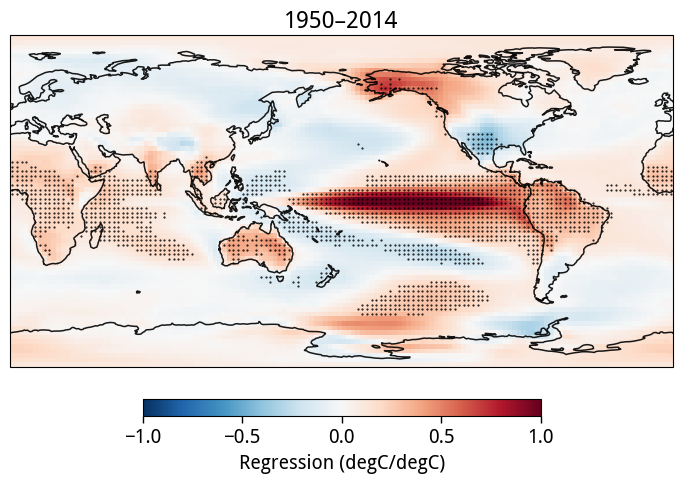

In [35]:
zz = ts_regr_cmip6_baseline.regr.mean('model')
sig_cmip6 = ts_regr_cmip6_baseline.pval

plot_baseline_teleconnection(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    sig_data=sig_cmip6,          # p-values (NOT binary)
    mode='cmip6',      # 'cmip6' or 'smile'
    p_threshold=0.05,
    agreement_threshold=0.8,
    cmap='RdBu_r',
    vmin=-1.0,
    vmax=1.0,
    cbar_label='Regression (degC/degC)',
    title='1950–2014',
)

plt.tight_layout()
plt.show()

In [36]:
def ttest_ind1d(a, b):
    _, p = stats.ttest_ind(a,b, equal_var=False)
    return p


def ttest_ind3d(da1, da2, dim='model'):
    return xr.apply_ufunc(ttest_ind1d, da1, da2, input_core_dims=[[dim], [dim]], exclude_dims={dim, dim}, vectorize=True, dask='parallelized')

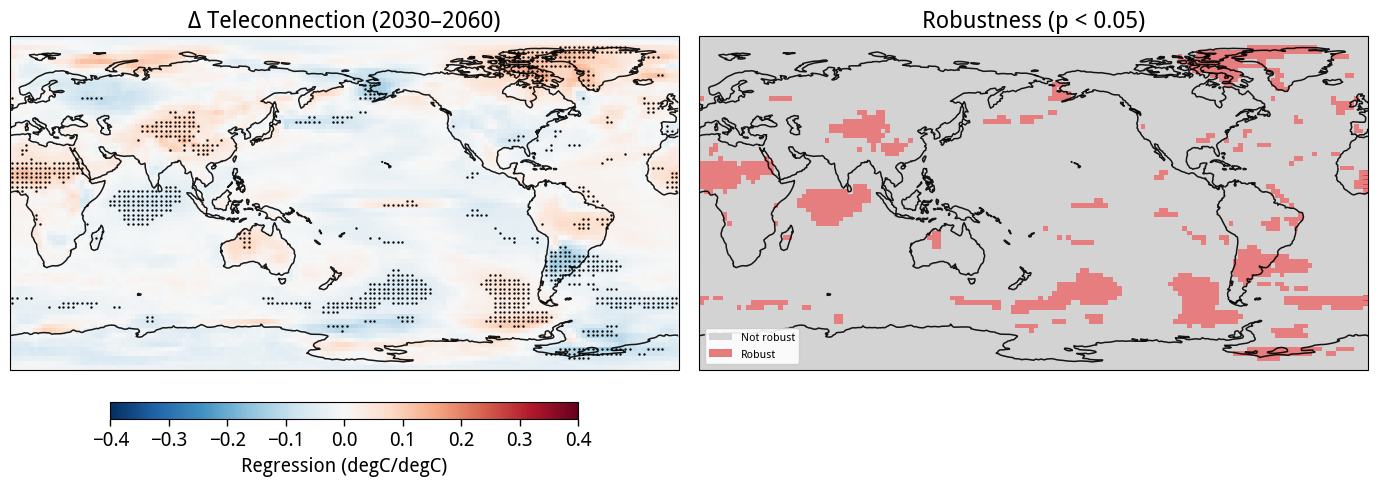

In [39]:
zz = delta_ts_regr_cmip6_midc.mean('model')
zp = ttest_ind3d(ts_regr_cmip6_baseline.regr, ts_regr_cmip6_midc.regr, dim='model')
zp1 = (np.abs(delta_ts_regr_cmip6_midc.mean('model'))/np.sqrt((ts_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_ts_regr_smile_midc_means.mean('smile'))/np.sqrt((delta_ts_regr_smile_midc_vars).mean('smile')))


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=None,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cbar_label='Regression (degC/degC)',
    title_main='Δ Teleconnection (2030–2060)',
    title_suffix='Robustness (p < 0.05)'
)

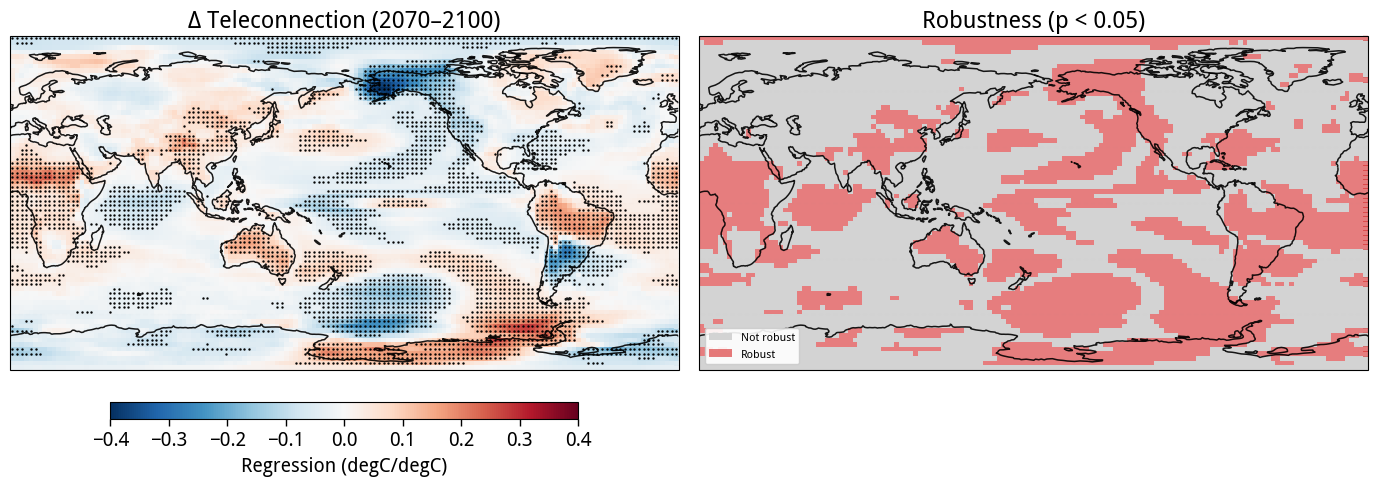

In [40]:
zz = delta_ts_regr_cmip6_endc.mean('model')
zp = ttest_ind3d(ts_regr_cmip6_baseline.regr, ts_regr_cmip6_endc.regr, dim='model')
zp1 = (np.abs(delta_ts_regr_cmip6_endc.mean('model'))/np.sqrt((ts_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_ts_regr_smile_endc_means.mean('smile'))/np.sqrt((delta_ts_regr_smile_endc_vars).mean('smile')))


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=None,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cbar_label='Regression (degC/degC)',
    title_main='Δ Teleconnection (2070–2100)',
    title_suffix='Robustness (p < 0.05)'
)

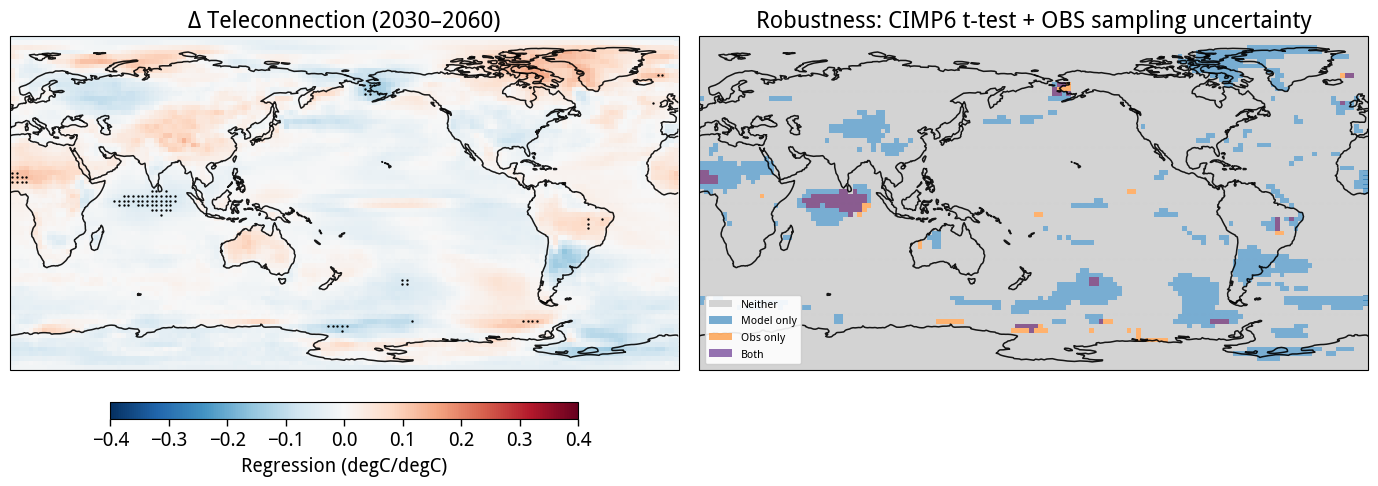

In [ ]:
zz = delta_ts_regr_cmip6_midc.mean('model')
# zp = funcs.mannwhitneyu3d(ts_regr_cmip6_baseline.regr, ts_regr_cmip6_midc.regr, dim='model')
zp = ttest_ind3d(ts_regr_cmip6_baseline.regr, ts_regr_cmip6_midc.regr, dim='model')
zp1 = (np.abs(delta_ts_regr_cmip6_midc.mean('model'))/np.sqrt((ts_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_ts_regr_smile_midc_means.mean('smile'))/np.sqrt((delta_ts_regr_smile_midc_vars).mean('smile')))
zp2 = (np.abs(delta_ts_regr_cmip6_midc.mean('model'))/np.sqrt((regridder_obs(delta_ts_regr_obs)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=zp2,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cbar_label='Regression (degC/degC)',
    title_main='Δ Teleconnection (2030–2060)',
    title_suffix='Robustness: CIMP6 t-test + OBS sampling uncertainty'
)

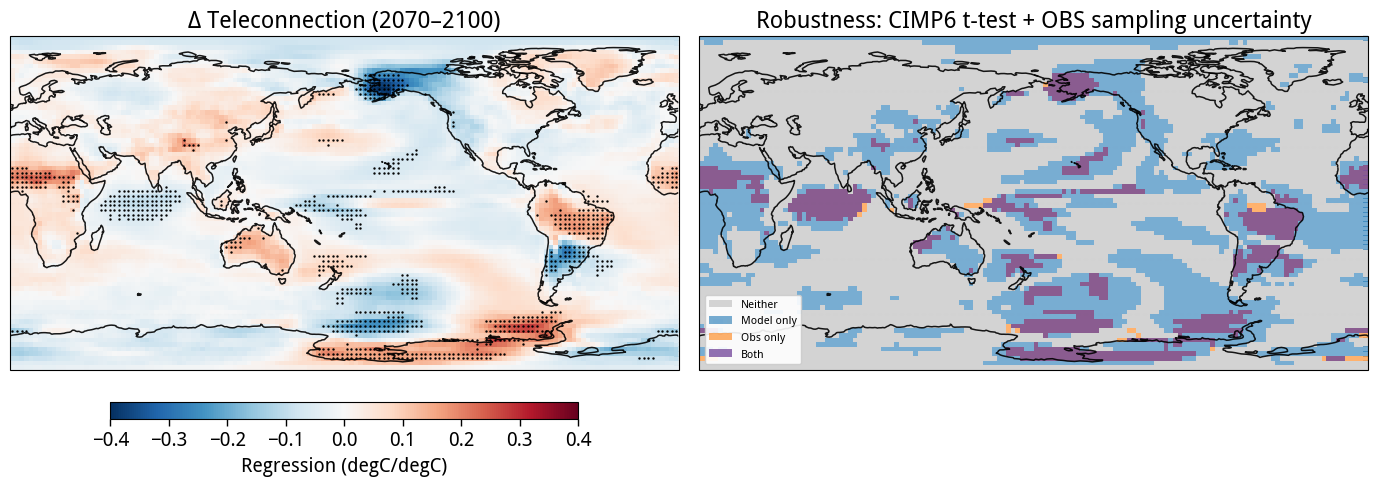

In [ ]:
zz = delta_ts_regr_cmip6_endc.mean('model')
zp = ttest_ind3d(ts_regr_cmip6_baseline.regr, ts_regr_cmip6_endc.regr, dim='model')
zp1 = (np.abs(delta_ts_regr_cmip6_endc.mean('model'))/np.sqrt((ts_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_ts_regr_smile_endc_means.mean('smile'))/np.sqrt((delta_ts_regr_smile_endc_vars).mean('smile')))
zp2 = (np.abs(delta_ts_regr_cmip6_endc.mean('model'))/np.sqrt((regridder_obs(delta_ts_regr_obs)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=zp2,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cbar_label='Regression (degC/degC)',
    title_main='Δ Teleconnection (2070–2100)',
    title_suffix='Robustness: CIMP6 t-test + OBS sampling uncertainty'
)

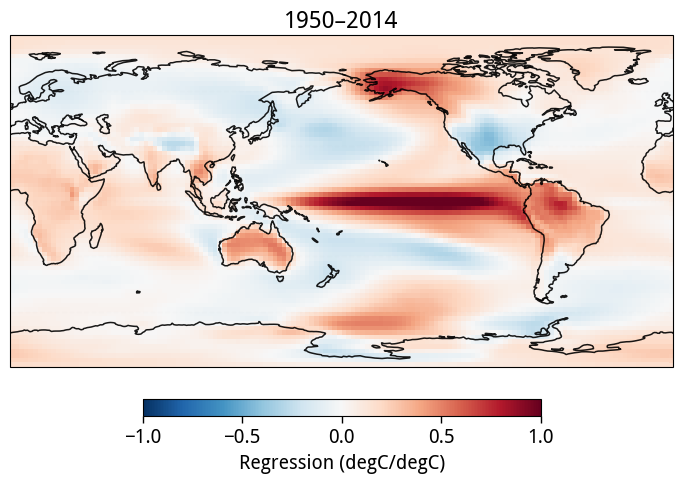

In [ ]:
zz = ts_regr_smile_baseline_means.mean('smile')
sig_smiles = ts_regr_smile_baseline_pvals

plot_baseline_teleconnection(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    sig_data=sig_smiles,          # p-values (NOT binary)
    mode='smile',      # 'cmip6' or 'smile'
    p_threshold=0.05,
    agreement_threshold=0.8,
    # smile_threshold=0.25,
    cmap='RdBu_r',
    vmin=-1.0,
    vmax=1.0,
    cbar_label='Regression (degC/degC)',
    title='1950–2014',
)

plt.tight_layout()
plt.show()

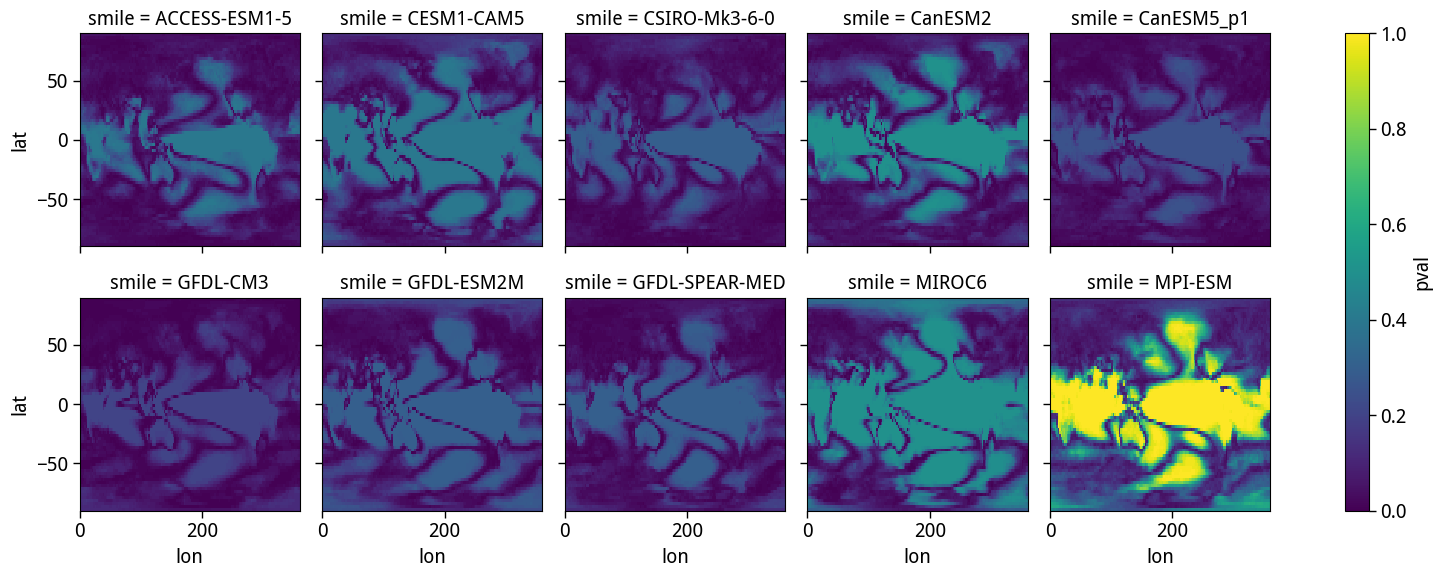

In [ ]:
(ts_regr_smile_baseline_pvals <= 0.05).mean('model').plot(col='smile', col_wrap=5)

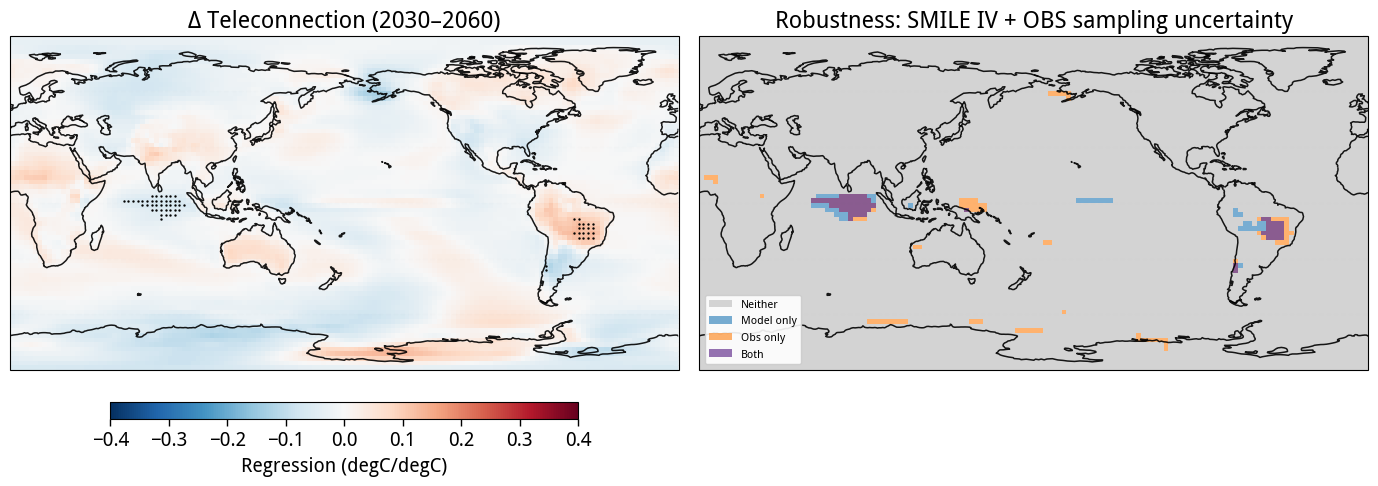

In [ ]:
zz = delta_ts_regr_smile_midc_means.mean('smile')
# zp = ttest_ind3d(ts_regr_smile_baseline_means.load(), delta_ts_regr_smile_midc_means.load(), dim='smile')
zp1 = (np.abs(delta_ts_regr_smile_midc_means.mean('smile'))/np.sqrt((ts_regr_smile_baseline_vars).mean('smile')))
zp2 = (np.abs(delta_ts_regr_smile_midc_means.mean('smile'))/np.sqrt((regridder_obs(delta_ts_regr_obs)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    snr_model=zp1,
    snr_obs=zp2,
    snr_threshold=1.5,
    use_pval=False,
    vmin=-0.4,
    vmax=0.4,
    cbar_label='Regression (degC/degC)',
    title_main='Δ Teleconnection (2030–2060)',
    title_suffix='Robustness: SMILE IV + OBS sampling uncertainty'
)

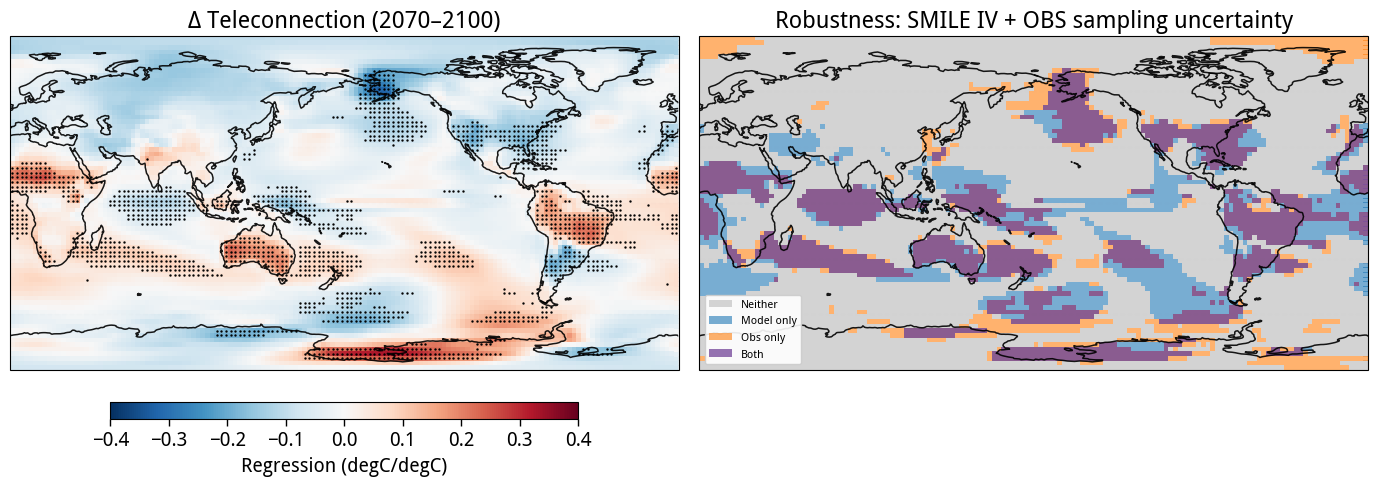

In [ ]:
zz = delta_ts_regr_smile_endc_means.mean('smile')
# zp = ttest_ind3d(ts_regr_smile_baseline_means.load(), delta_ts_regr_smile_endc_means.load(), dim='smile')
zp1 = (np.abs(delta_ts_regr_smile_endc_means.mean('smile'))/np.sqrt((ts_regr_smile_baseline_vars).mean('smile')))
zp2 = (np.abs(delta_ts_regr_smile_endc_means.mean('smile'))/np.sqrt((regridder_obs(delta_ts_regr_obs)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    snr_model=zp1,
    snr_obs=zp2,
    snr_threshold=1.0,
    use_pval=False,
    vmin=-0.4,
    vmax=0.4,
    cbar_label='Regression (degC/degC)',
    title_main='Δ Teleconnection (2070–2100)',
    title_suffix='Robustness: SMILE IV + OBS sampling uncertainty'
)

In [41]:
M_baseline = ts_regr_smile_baseline_means.var('smile')
I_baseline = ts_regr_smile_baseline_vars.mean('smile')
T_baseline = M_baseline + I_baseline

In [42]:
M_midc = delta_ts_regr_smile_midc_means.var('smile')
I_midc = delta_ts_regr_smile_midc_vars.mean('smile')
T_midc = M_midc + I_midc

In [43]:
M_endc = delta_ts_regr_smile_endc_means.var('smile')
I_endc = delta_ts_regr_smile_endc_vars.mean('smile')
T_endc = M_endc + I_endc

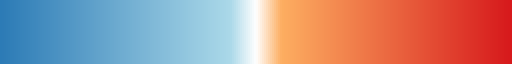

In [44]:
# Define colors
cmap = mcolors.LinearSegmentedColormap.from_list(
    "model_vs_internal",
    [
        (0.0, "#2c7bb6"),   # blue (internal variability dominates)
        (0.45, "#abd9e9"),  # light blue
        (0.50, "#ffffff"),  # neutral
        (0.55, "#fdae61"),  # light orange
        (1.0, "#d7191c"),   # red (model dominates)
    ]
)
cmap

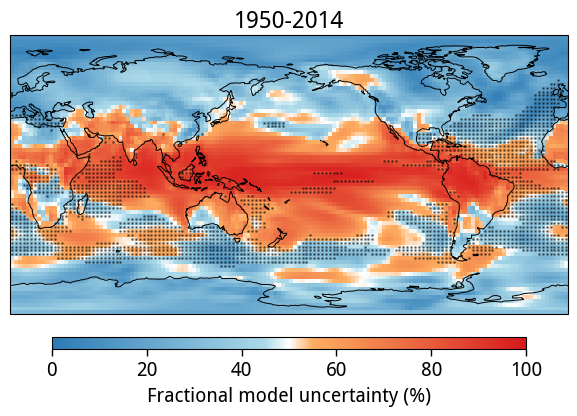

In [46]:
zz = (M_baseline / (M_baseline + I_baseline + 1e-12)) * 100

xx, yy = np.meshgrid(zz.lon, zz.lat)

T_baseline = M_baseline + I_baseline

fig = plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))

# ---------------------------
# Plot main field
# ---------------------------
im = zz.plot(
    ax=ax,
    vmin=0,
    vmax=100,
    cmap=cmap,
    transform=ccrs.PlateCarree(),
    cbar_kwargs=dict(
        orientation='horizontal',
        shrink=0.85,
        aspect=40,
        pad=0.05,
        label='Fractional model uncertainty (%)'
    )
)

# ---------------------------
# Stippling: low total uncertainty regions
# ---------------------------
low_unc = T_baseline < np.nanpercentile(T_baseline, 20)

ax.scatter(
    xx[low_unc],
    yy[low_unc],
    s=1,
    color='k',
    alpha=0.4,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# ---------------------------
# Map aesthetics
# ---------------------------
ax.coastlines(linewidth=0.7)
ax.set_global()
ax.set_title('1950-2014')

plt.tight_layout()
plt.show()



# NOTE -  Stippling indicates regions where total uncertainty (M + I) lies in the lowest quintile of the domain distribution, representing areas where fractional partitioning is less informative due to weak overall uncertainty magnitude

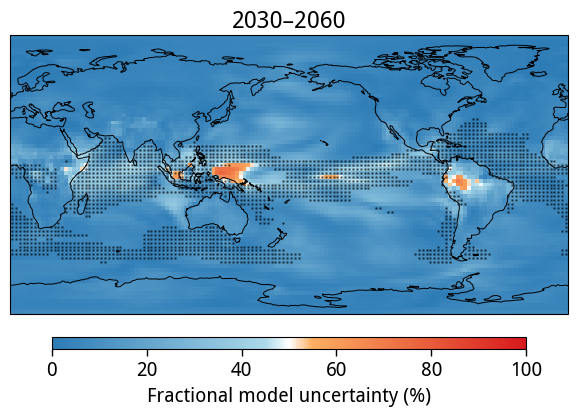

In [47]:
zz = (M_midc / (M_midc + I_midc + 1e-12)) * 100

xx, yy = np.meshgrid(zz.lon, zz.lat)

T_midc = M_midc + I_midc

fig = plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))

# ---------------------------
# Plot main field
# ---------------------------
im = zz.plot(
    ax=ax,
    vmin=0,
    vmax=100,
    cmap=cmap,
    transform=ccrs.PlateCarree(),
    cbar_kwargs=dict(
        orientation='horizontal',
        shrink=0.85,
        aspect=40,
        pad=0.05,
        label='Fractional model uncertainty (%)'
    )
)

# ---------------------------
# Stippling: low total uncertainty regions
# ---------------------------
low_unc = T_midc < np.nanpercentile(T_midc, 20)

ax.scatter(
    xx[low_unc],
    yy[low_unc],
    s=1,
    color='k',
    alpha=0.4,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# ---------------------------
# Map aesthetics
# ---------------------------
ax.coastlines(linewidth=0.7)
ax.set_global()
ax.set_title('2030–2060')

plt.tight_layout()
plt.show()



# NOTE -  Stippling indicates regions where total uncertainty (M + I) lies in the lowest quintile of the domain distribution, representing areas where fractional partitioning is less informative due to weak overall uncertainty magnitude

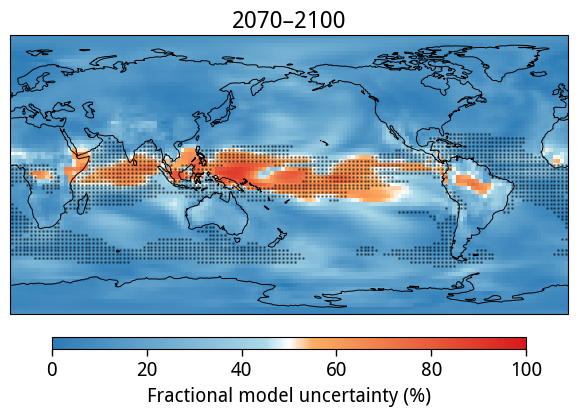

In [48]:
zz = (M_endc / (M_endc + I_endc + 1e-12)) * 100

xx, yy = np.meshgrid(zz.lon, zz.lat)

T_endc = M_endc + I_endc

fig = plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))

# ---------------------------
# Plot main field
# ---------------------------
im = zz.plot(
    ax=ax,
    vmin=0,
    vmax=100,
    cmap=cmap,
    transform=ccrs.PlateCarree(),
    cbar_kwargs=dict(
        orientation='horizontal',
        shrink=0.85,
        aspect=40,
        pad=0.05,
        label='Fractional model uncertainty (%)'
    )
)

# ---------------------------
# Stippling: low total uncertainty regions
# ---------------------------
low_unc = T_endc < np.nanpercentile(T_endc, 20)

ax.scatter(
    xx[low_unc],
    yy[low_unc],
    s=1,
    color='k',
    alpha=0.4,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# ---------------------------
# Map aesthetics
# ---------------------------
ax.coastlines(linewidth=0.7)
ax.set_global()
ax.set_title('2070–2100')

plt.tight_layout()
plt.show()



# NOTE -  Stippling indicates regions where total uncertainty (M + I) lies in the lowest quintile of the domain distribution, representing areas where fractional partitioning is less informative due to weak overall uncertainty magnitude

In [49]:
plot_list = [
    (T_baseline) - ts_regr_cmip6_baseline.regr.var('model'),
    (T_midc) - ts_regr_cmip6_midc.regr.var('model'),
    (T_endc) - ts_regr_cmip6_endc.regr.var('model'),
]

titles_list = [
    'Baseline',
    'Mid century',
    'End century',
]

labels_list = [
    'a',
    'b',
    'c',
]

In [50]:
# ### Fractional model uncertainty in Base period and in mid century changes and end century changes

# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
# plot_maps(xx, yy, plot_list, titles_list, labels_list, cmap='bwr', levels=np.linspace(-0.1, 0.1, 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#             nrows=1, ncols=3, figsize=(20,8), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
#             cbar_kwargs=dict(orientation='horizontal', label='Relative uncertainty', aspect=45, shrink=0.5, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

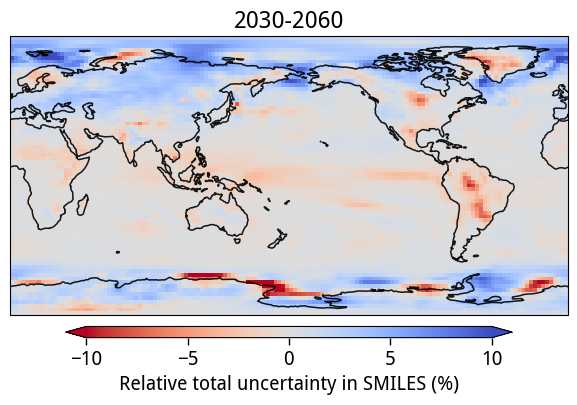

In [51]:
zz = ((T_midc) - ts_regr_cmip6_midc.regr.var('model'))*100

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -10, vmax=10, cmap='coolwarm_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Relative total uncertainty in SMILES (%)'), transform=ccrs.PlateCarree())


ax.set_title('2030-2060')
plot_background(ax)
plt.tight_layout()



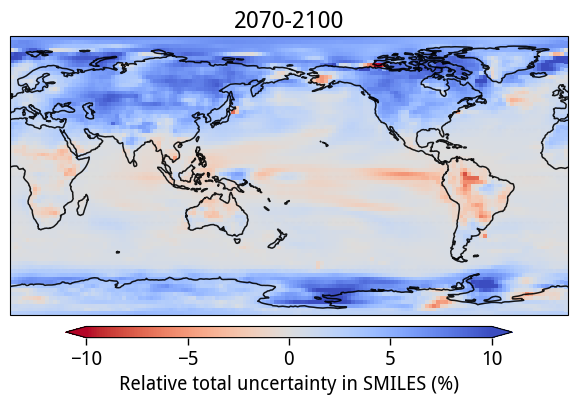

In [52]:
zz = ((T_endc) - ts_regr_cmip6_endc.regr.var('model'))*100

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -10, vmax=10, cmap='coolwarm_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Relative total uncertainty in SMILES (%)'), transform=ccrs.PlateCarree())


ax.set_title('2070-2100')
plot_background(ax)
plt.tight_layout()

